### What is Graph RAG?
A type of RAG system where you create a Knowledge graph based on all the information you have (docs, pdfs, text etc...) and use that to retrieve information. 

A knowledge graph is basically you have all your chunks connected to each other in a defined way. The knowledge is not just scattered as chunks. 

A knowledge graph represents information using three basic elements:
- Node: an entity, such as a person, company, or product.
- Edge / relationship: how two entities are connected.
- Property: additional information about a node or relationship.

For ex: 
- In Vector RAG : suppose you have chunks of info about - viruses, mutations, proteins, drugs 
- In Graph RAG : You will have a connected graph of how those things are connected, so when you try to retrieve info about X virus cause Y proteins to Z mutation - we can do that since info about all of them is well connected

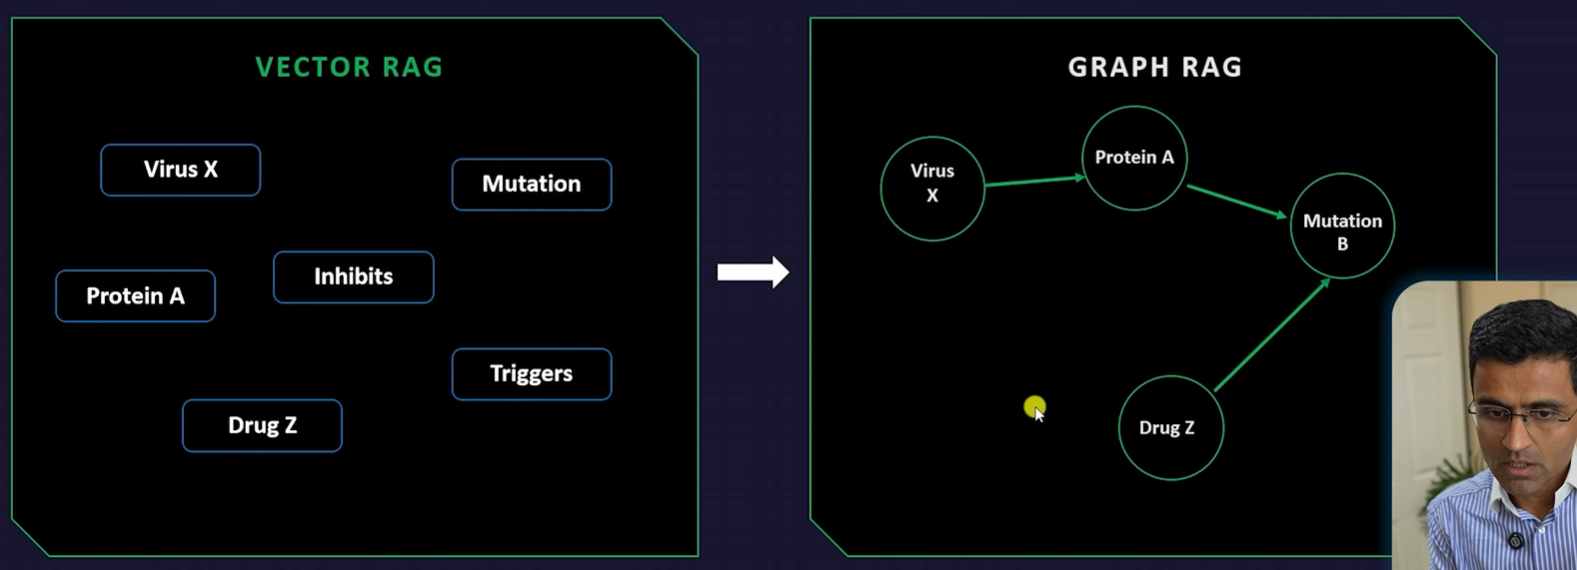

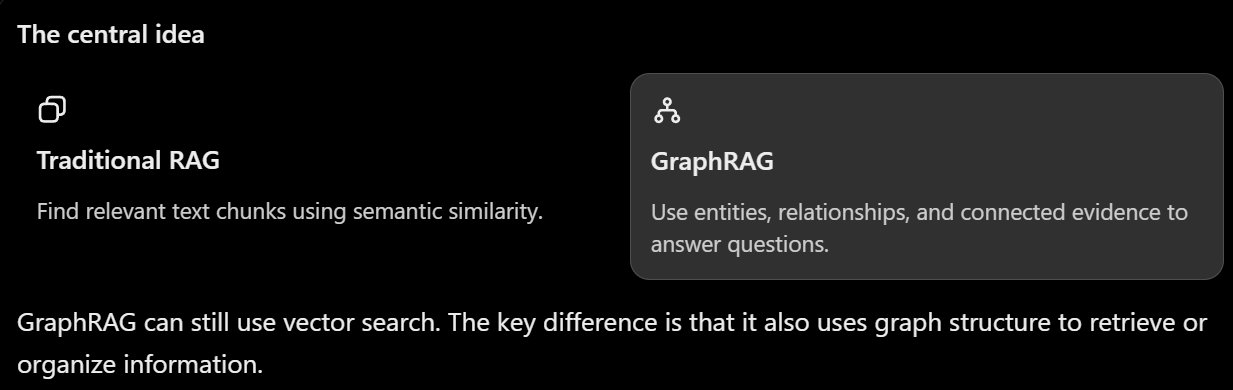

### Indexing

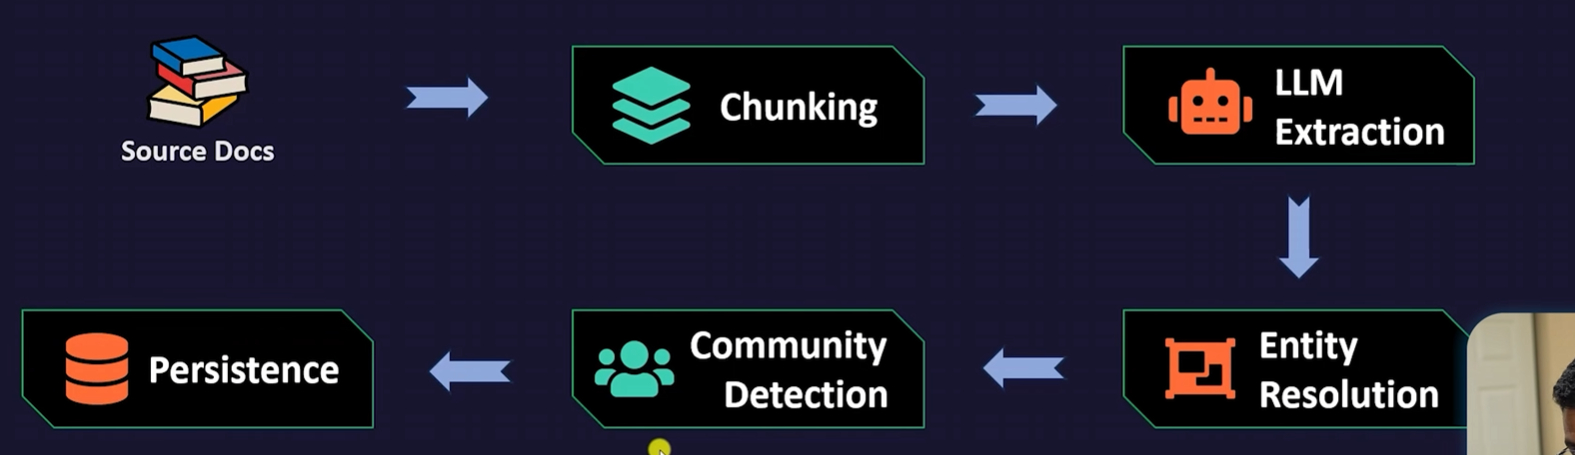

### Retrieval

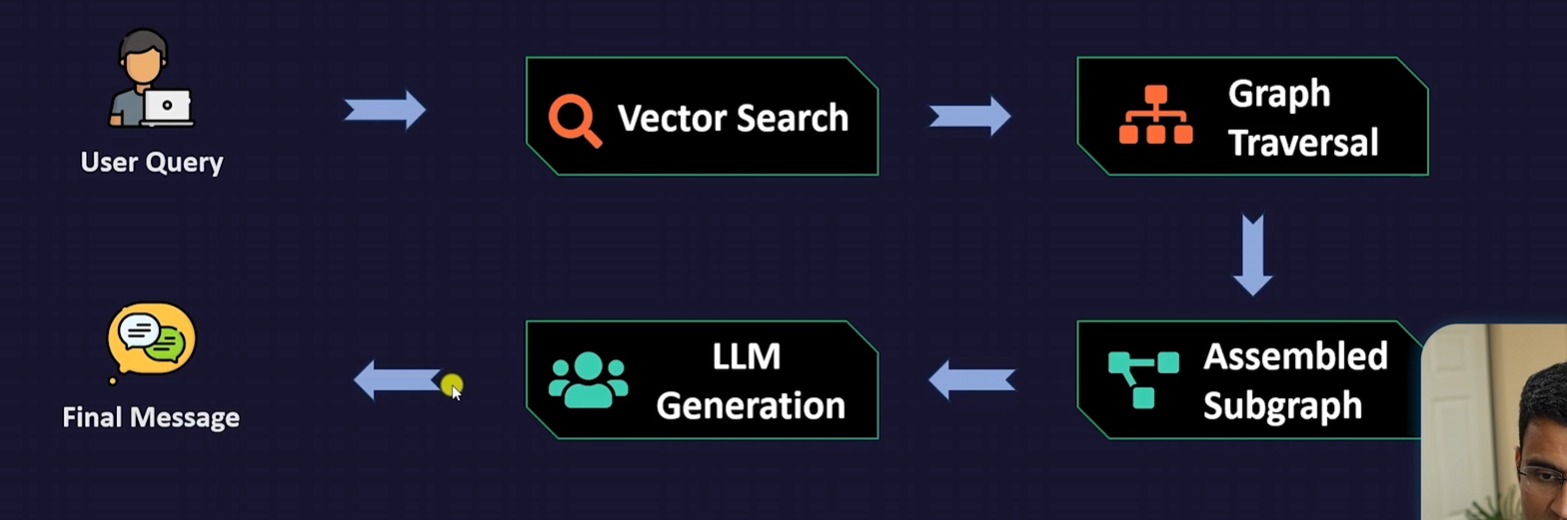

### Difference

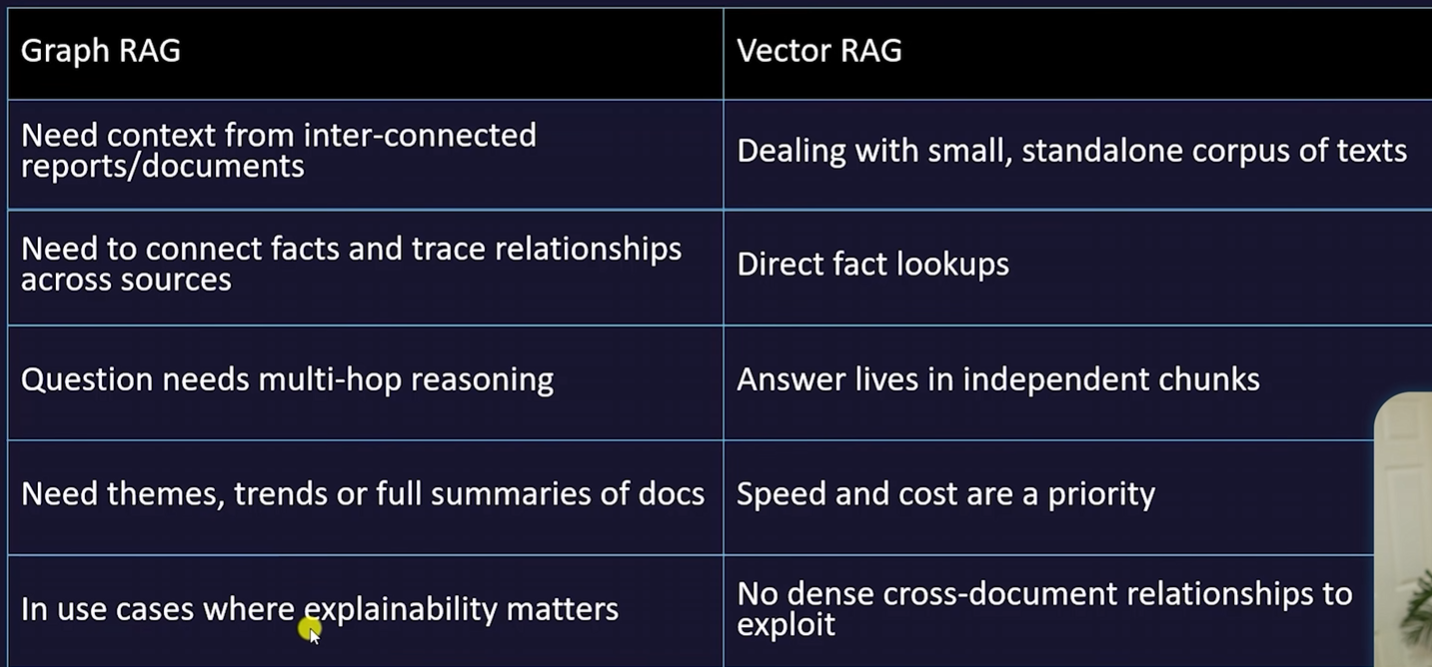

#### Benefits

* [**Link based on existing metadata:**](https://datastax.github.io/graph-rag/guide/get-started/)
  Use existing metadata fields without additional processing. Retrieve more from an
  existing vector store!

* [**Change links on demand:**](https://datastax.github.io/graph-rag/guide/edges/)
  Edges can be specified on-the-fly, allowing different relationships to be traversed
  based on the question.

* [**Pluggable Traversal Strategies:**](https://datastax.github.io/graph-rag/guide/strategies/)
  Use built-in traversal strategies like Eager or MMR, or define custom logic to select
  which nodes to explore.

* [**Broad compatibility:**](https://datastax.github.io/graph-rag/guide/adapters/)
  Adapters are available for a variety of vector stores with support for additional
  stores easily added.

### Implementation

The GraphRetriever from the langchain-graph-retriever package provides a LangChain retriever that combines __unstructured similarity search on vectors__ with __structured traversal of metadata properties__. _This enables graph-based retrieval over an existing vector store._

- Install package

In [10]:
!pip install -qU langchain-graph-retriever
!pip install -qU langchain-graph-retriever[chroma]

- Populate vector store

Note -    
There is something called - filtering based on metadata, and nested metadata   
Metadata is the extra info wrapped around a Document

A nested metadata looks like - 
```json
{
    "source": "notes.pdf",
    "details": {
        "topic": "AI",
        "difficulty": "beginner"
    }
}
```

A flattened metadata looks like - 
```json
{
    "source": "notes.pdf",
    "details_topic": "AI",
    "details_difficulty": "beginner"
}
```
Now - There are some vector dbs that cannot filter documents based on _nested_ metadata.    
A GraphRAG pipeline may attach structured information to documents, including entity details and relationships. If that information contains nested metadata, the vector store may not be able to filter it as expected.

We use a transformer - `ShreddingTransformer` to flatten the nested metadata in that case   
The data flow is:   
Documents → ShreddingTransformer → Chroma Vector Store → Retrieval

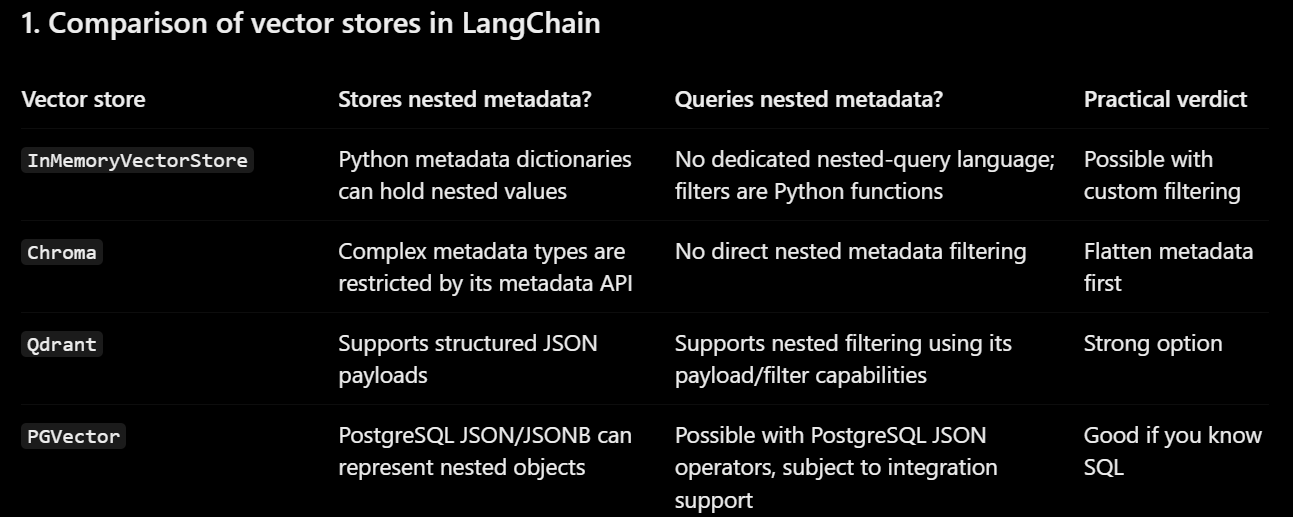

In [11]:
from langchain_graph_retriever.transformers import ShreddingTransformer
from langchain_chroma.vectorstores import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

In [12]:
embedding_model = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

chroma = Chroma(
    embedding_function=embedding_model,
    persist_directory="Chroma_VectorStore",
    collection_name="GraphRAG_test"
)